# E76: Does a masked term in teacher training keep Qwen3-1.7B's decomposition faithful?

*2026-11-04, D1, `qwen-decomp-lead`. D1 is a map on Qwen3-1.7B that keeps the decomposition faithful for a real update, judged by a test that can fail a bad placement. Record: `reports/analyses/2026-11-04_analysis_e76-masked-teacher.md`. Independent check: `reports/reviews/2026-11-04_review_e76-b-works.md`.*

## The answer

Adding a masked term to teacher training earned the filed label "works" on one update, one seed and 200 columns per matrix, and the label stands. It says less than its name, so we do not yet have a faithful map on this model. Taking the fine-tuned clean model as reference, the masked model's KL fell nearly fivefold, yet stays 6.6 times the original decomposition's own. The change grew to 3.4 times the update's squared size. Whether the fall is agreement or softness is unread.

**Something unexpected happened that I cannot explain.** We leaned that the all-masked arm would fail on where its change sits or fail to learn, and that the routed arm would barely beat the clean term. Both leans were false. The filed verdict stands as filed, and the caveats below narrow what it means without explaining the reversal.


## What we were trying to test

D1 needs a way to carry the decomposition across a real update. We start from W0, Qwen3-1.7B before the update, and FT, W0 plus the first fine-tune's update δW. In a masked forward each of the 196 matrices rebuilds its output from its subcomponents, each multiplied by a mask $m = g + (1-g)u$, with $g$ the causal importance from Γ on W0 and $u$ uniform on 0 to 1.

Teacher training moves about 200 often-on columns per matrix so that the changed model, the student, copies FT, with Γ and Δ frozen. Its loss is KL(FT clean ‖ student clean), with FT as the reference. We asked whether a second term, KL(FT clean ‖ student masked), can pull the masked output along too.

Four arms ran on one L40, each rate 1e-6 with Adam:

- **A, clean term alone.** The filed recipe, and the reference for how far masked reads fall with no masks in the loss.
- **B, clean plus masked term with all 196 masked.** It asks whether the masks can be trained against.
- **L, clean plus masked term under the library's routing.** Each position masks a uniform number of matrices and the rest read the student's full weights. It tests whether routed-out matrices carry the update round the masks.
- **C, the control, first and for 300 steps.** B's loss with a teacher that is W0 plus a random change of 0.01 nats. It shows the masked gradient trains, and its fall sets the band.

Readings use eight maths rows that training never sees, with one fixed mask draw per row. KL(FT clean ‖ student masked) is read all-masked for every arm. W0 reads 1.33 on it and the yardstick is W0's own masked KL, KL(W0 clean ‖ W0 masked), at 0.042. Squared size is the sum over weights of the squared change, and δW reads 3.49. The two amendments keep each saved change on some blocks only and read it again, with no training.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path("../experiments/qwen_masked_teacher")
RES, FIG = ROOT / "results", ROOT / "figures"

def load(name):
    return json.loads((RES / name).read_text())

def show(name):
    display(Image(filename=str(FIG / name), width=760))

def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

SCORE, S0, A1, A2, DW = (load(f) for f in ("score.json", "stage0.json", "amend1.json", "amend2.json", "dw_blocks.json"))
LAST, OWN = SCORE["last"], S0["K0_8_fp32"]


## What we expected, and why

- **Filed "works" rule.** Clean KL at or below 0.09, distance from W0 at or below 0.94, late share at or below 3, and the masked KL below A's by more than C's fall. Late share is the share of the change's squared size in blocks 21 to 27, over δW's same share.
- **B would fail, medium lean.** An earlier run found small changes at early blocks barely reach the logits with all matrices masked, so we expected a late-only change or no learning.
- **L would barely beat A, weak lean.** Routed-out matrices could lower the training term with the masks doing no work.
- **C near A on late share.** Its teacher is random, so we saw no reason for it to pile up late.
- **The fall sits late, medium lean.** At least 0.8 of B's fall from blocks 21-27 alone, at most 0.1 from early blocks alone.

## What we observed

### Does training on the masked term lower it, and how near does it get?


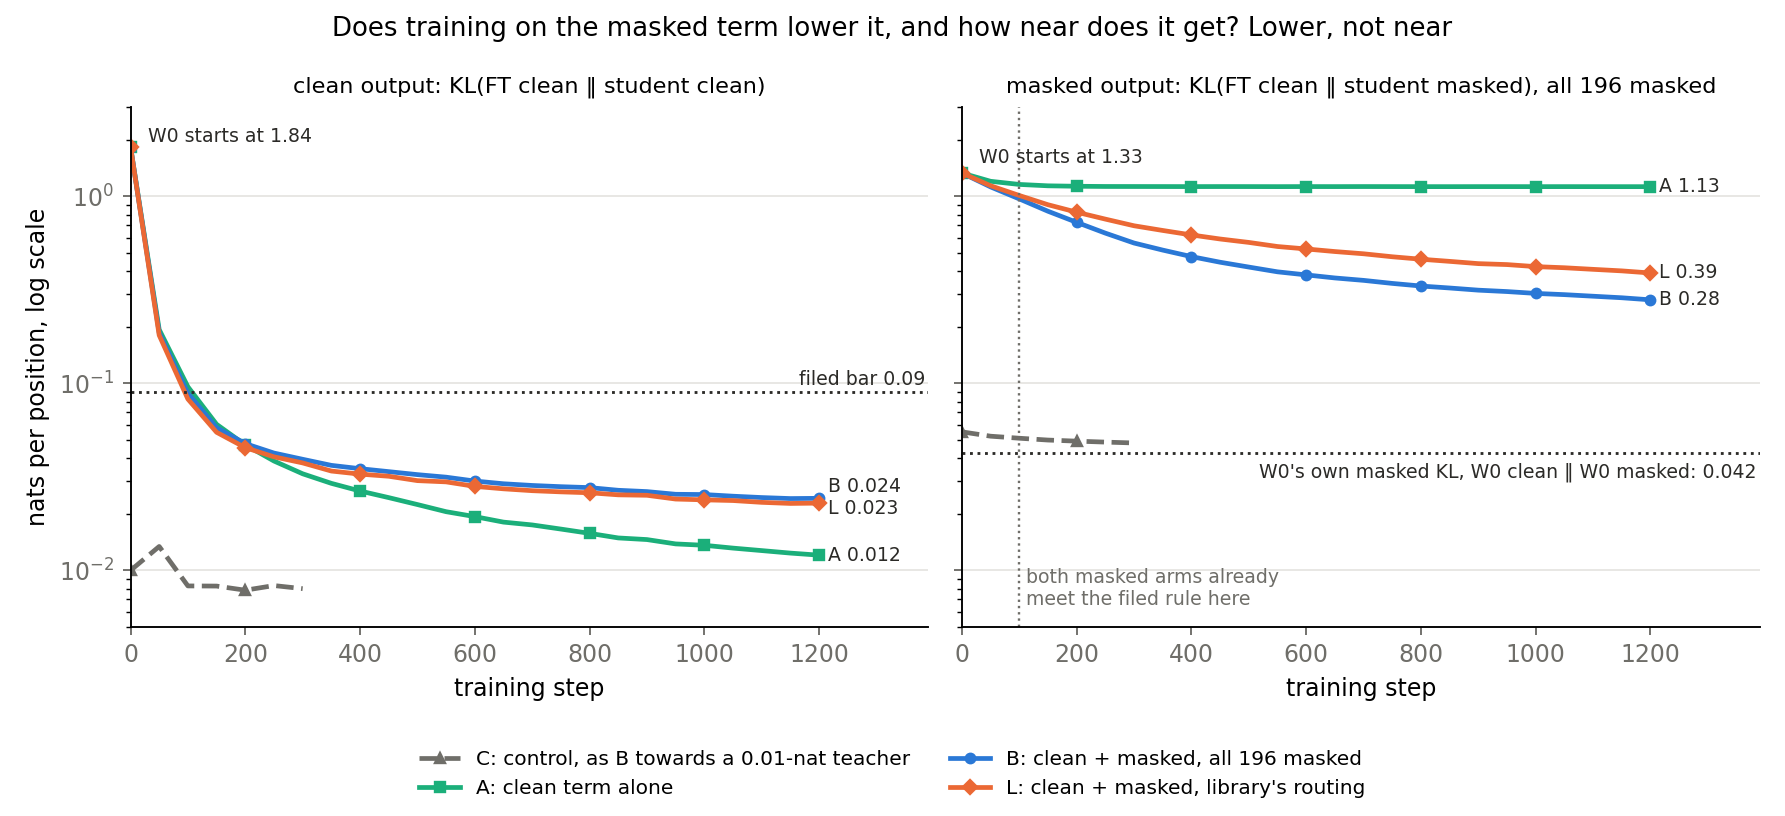

In [2]:
show("two_terms.png")


**Reading it.** It lowers it a long way, and it does not get near the reference. On the right, KL(FT clean ‖ student masked) ends at 0.28 in B and 0.39 in L, against 1.13 in A. W0 starts at 1.33, and W0's own masked KL is the dotted line at 0.042, so B stays 6.6 times above it. On the left, every arm clears the clean bar.

The filed verdict is "B works", and it stands. The rule is weaker than the word: its masked clause only compares with A and has no bar on the value. Applied at every reading, it holds for both masked arms from step 100, where B still reads 0.97. So this is not "D1 has its map".


In [3]:
rows = [["W0", "1.842", "no change", f"{A1['W0']['iv']:.3f}", f"{A1['W0']['iv'] / OWN:.1f}"]]
for arm in "ABL":
    r = LAST[arm]
    rows.append([arm, f"{r['i']:.4f}", f"{sum(r['blocks']) / DW['sum']:.2f}", f"{r['iv']:.3f}", f"{r['iv'] / OWN:.1f}"])
table(["state", "KL(FT clean ‖ clean)", "squared size over δW's", "KL(FT clean ‖ masked)", "over W0's own masked KL"], rows)


| state | KL(FT clean ‖ clean) | squared size over δW's | KL(FT clean ‖ masked) | over W0's own masked KL |
|---|---|---|---|---|
| W0 | 1.842 | no change | 1.334 | 31.5 |
| A | 0.0121 | 0.52 | 1.127 | 26.6 |
| B | 0.0243 | 3.42 | 0.280 | 6.6 |
| L | 0.0229 | 2.36 | 0.390 | 9.2 |

### What does the masked fall cost in weight size?


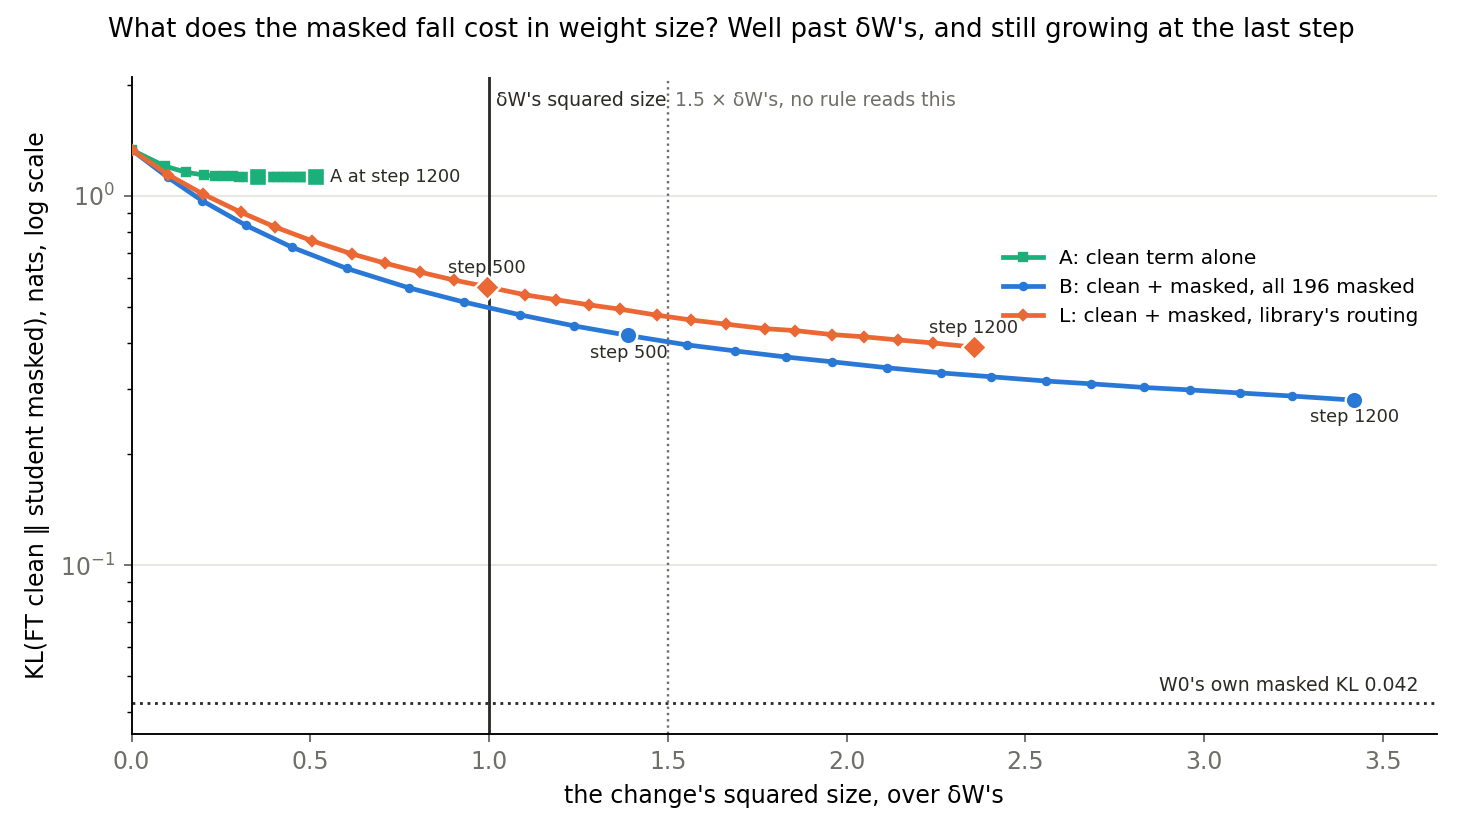

In [4]:
show("size_vs_fall.png")


**Reading it.** It costs far more than the update's own size, and this is the headline caveat. B ends at 3.4 times δW's squared size and A at 0.52 times, and no filed rule reads size. There is no plateau: B's size is still growing about 10 per 1000 steps at the end. Most of the excess bought little, since B passes δW's size at about step 400 and gains only 0.14 nats for 7 more of squared size after step 500. Part of every size here may be Adam's walk rather than signal: the check finds A's near what noise alone gives, and B's excess real only late.

### Where does each change sit?


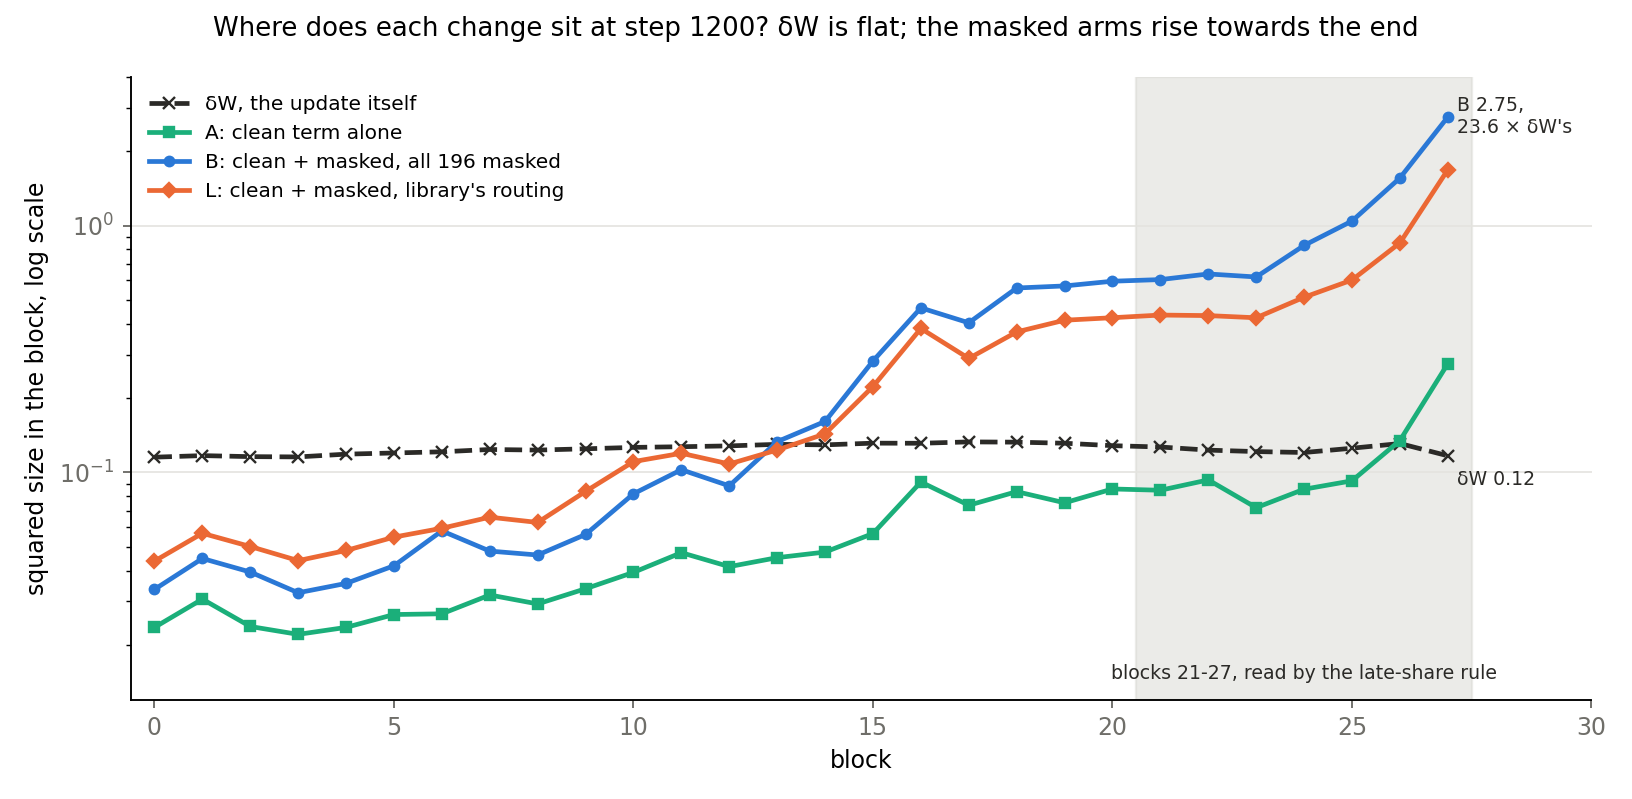

In [5]:
show("by_block.png")


**Reading it.** δW is flat and the masked arms rise towards the end. B's last block is 23.6 times δW's, and 68% of its squared size sits in blocks 21-27, against δW's 25%. The student copies FT's outputs and not its weights: by the check's recomputation, every arm ends further from FT's weights than W0 started. Whether components still mean what they did is unread.

### Does the late-share rule show the change is placed like the update?


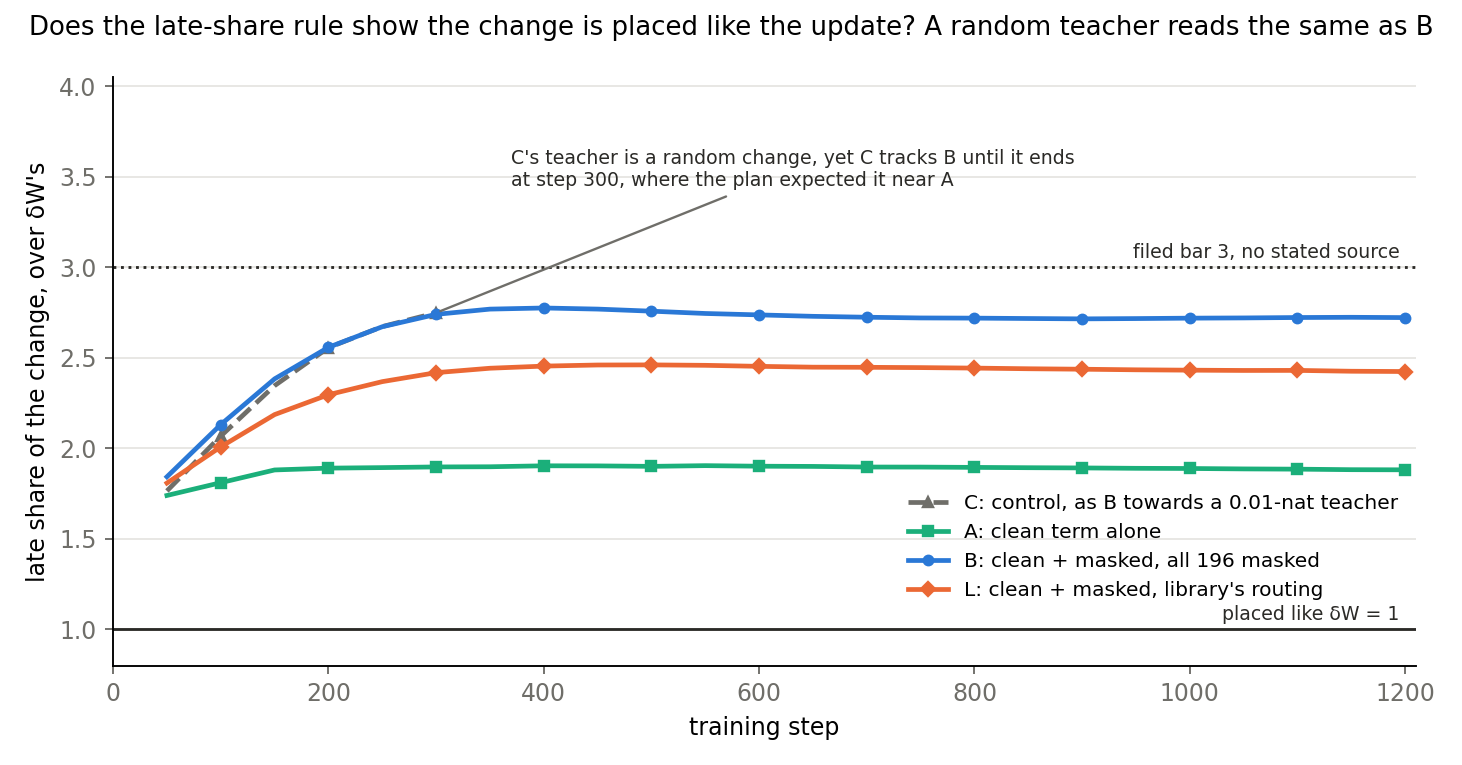

In [6]:
show("late_share.png")


**Reading it.** No. B passes at 2.72 against a bar of 3, but C reads 2.75 at step 300 with a random teacher. The plan expected C near A's 1.88, so that expectation missed. The masked term with Adam pushes size late whatever the teacher, so this reading does not come from the update. The 3 has no stated source, and a bar of 2.5 would have changed the outcome to "B fails, L works". The rule was filed and stands, as weak support.

### Which blocks lower the masked term?


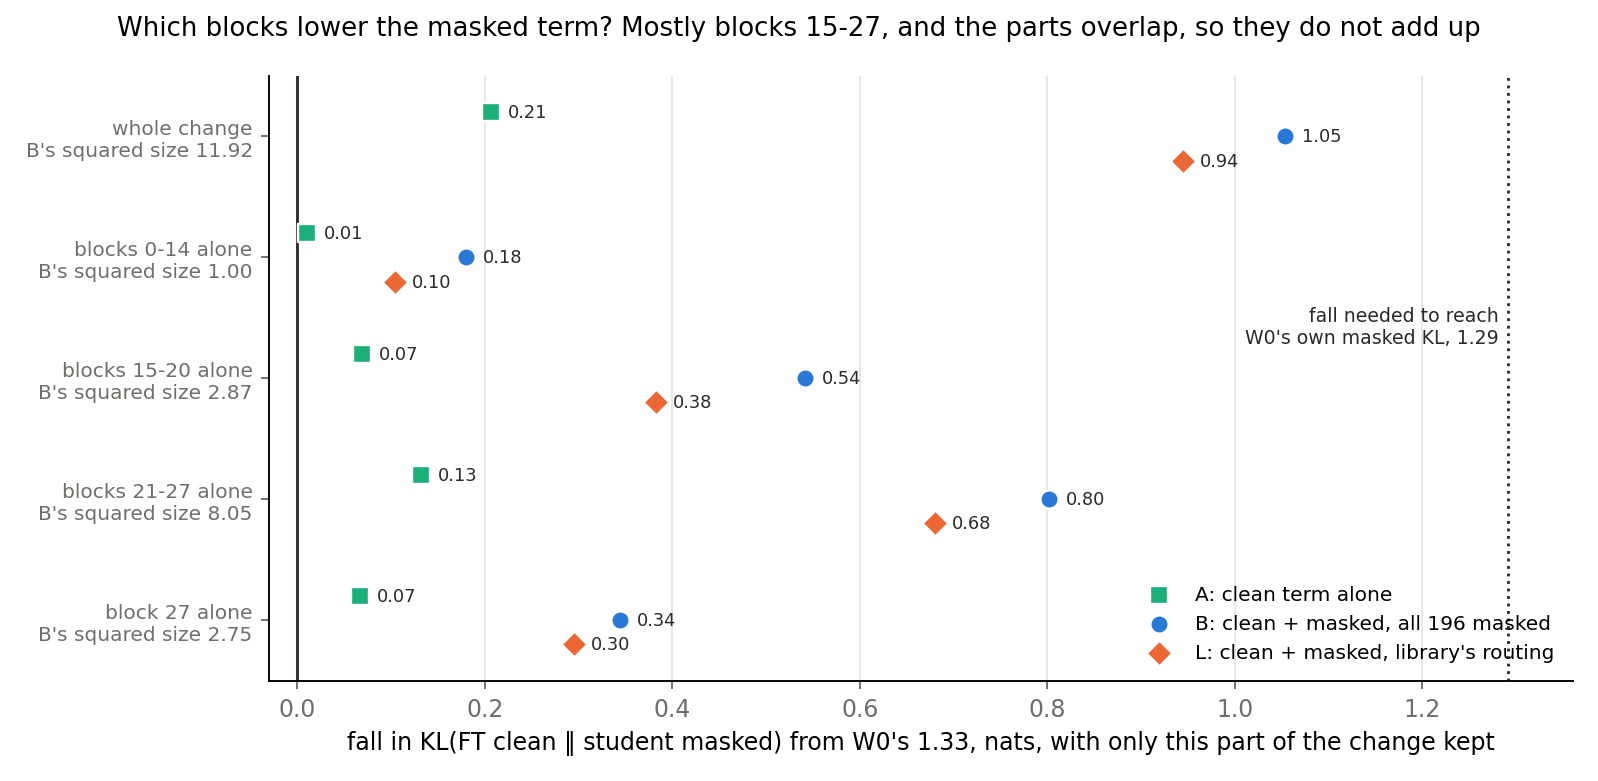

In [7]:
show("parts.png")


**Reading it.** Mostly blocks 15-27, with real overlap. Each row keeps only that part of the change, so the shares do not add: for B they sum to 1.44. B's blocks 21-27 alone give 0.76 of its fall, a narrow miss of our lean.

B's blocks 0-14 alone lower KL(FT clean ‖ student masked) by 0.18 nats at squared size 1.00, against A's 0.01 at 0.49. So a trained change in early blocks does reach the logits with all matrices masked, which narrows the earlier statement that a masked term can hardly teach them. Whether this is size or direction is unmeasured. It does not contradict the earlier reading on small changes, since that read a second-order quantity and this a first-order fall.

### Why did the earlier last-matrix control read below 1?


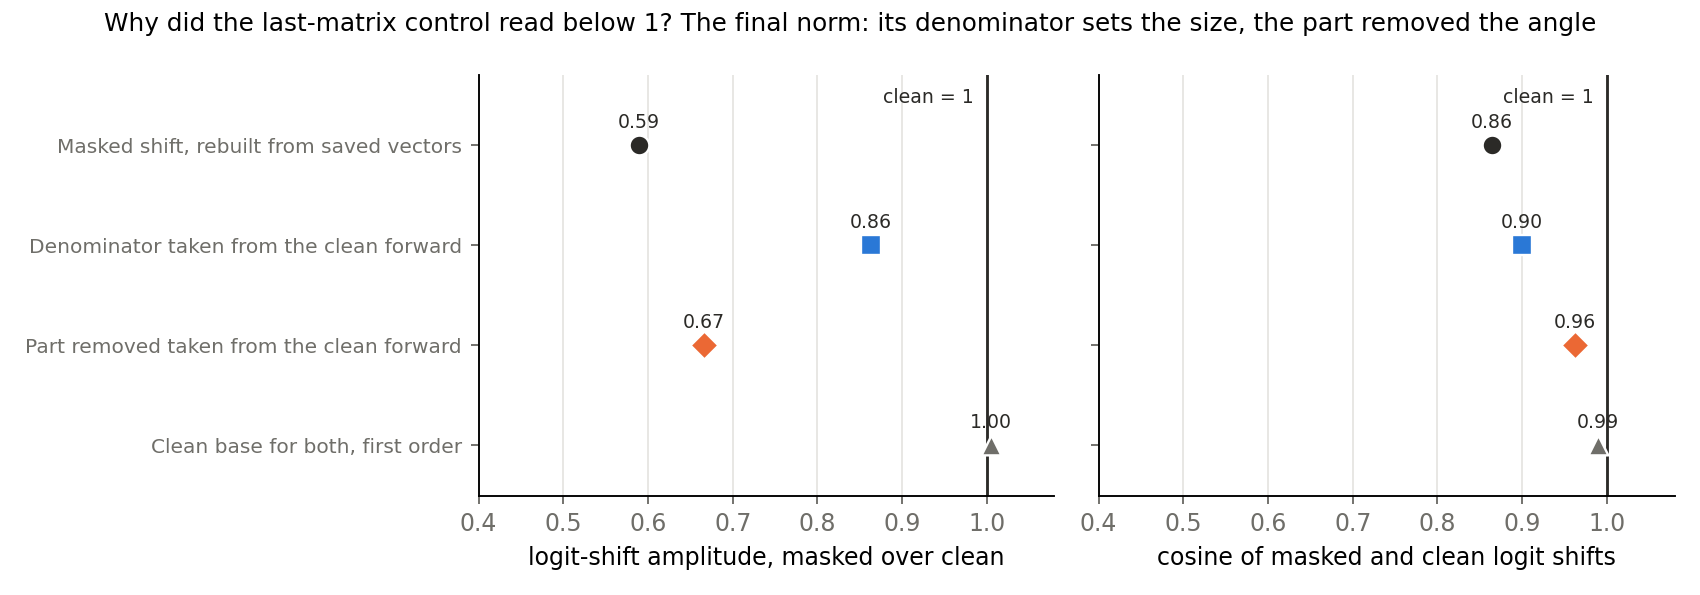

In [8]:
show("hook.png")


**Reading it.** Because of the final norm, and the hook is clear. That control masked only the last matrix, and read amplitude 0.59 and cosine 0.86 where the plan expected near 1. Rebuilding both shifts from saved vectors gives the same numbers, so nothing else is between them. Two causes act. The norm's input is 1.43 times larger under the mask, and taking only that denominator from clean moves amplitude to 0.86. The norm also removes the part of a change along its input, and taking only that from clean moves cosine to 0.96. It covers one update and 32 rows, under fixed masks.

## What we learned

A masked term can be trained against with the original masks frozen and all 196 matrices masked, which we doubted. That is progress towards D1, because masked reads had barely responded to any update before. It is not D1's map: the masked KL stays well above the original decomposition's own, the change is several times the update's squared size and growing, and the rule that passed it cannot see size. Early blocks are not deaf to a trained change. All of this is provisional.

## How compelling is the evidence

- **Coverage.** The update u1 alone, one seed, one reading draw, 200 columns per matrix holding 0.835 of the sum of $g$, eight maths rows. No FineWeb row is read. B beats A by 120 times C's band, so the sign is safe, but 0.28 has no error bar.
- **KL with FT as reference rewards softness.** FT is softer than W0, so a soft student already sits nearer it. **Agreement is unread**: neither top tokens nor entropy was saved.
- **Row 5, the cleanest held-out row.** It has no chat template and shares no long run with training. B falls 57% there, against 77% to 81% on the other seven, and stays below A.
- **Masks from W0.** The student is read under masks made on W0's forward, a mix no deployed state would run.
- **Independent check.** It re-ran the rules, recomputed sizes from saved offsets and found no bug. It ran no model forward.

## Surprises

1. Both leans on the arms were false. B and L read "works", and L's masked KL fell 65% below A's against a lean of under 10%.
2. C's late share read 2.75 against "near A's" at 1.88.
3. Blocks 0-20 alone gave 0.61 of B's fall against a lean of at most 0.1, and blocks 0-14 alone gave 0.17.

## What next

1. **E79, running after this, a read of the saved changes at no cost.** It reads agreement, entropy, FineWeb rows and the student under its own masks. We do not guess its outcome here. Its plan is `reports/plans/2026-11-04_plan_e79-agreement-or-softness.md`.
2. **B or A on size, for the user, after E79.** B lowers the masked term far more at 3.4 times δW's squared size, and A stays at 0.52 times. Whether B's fall is agreement decides it.
3. **A size-limited B and a random-teacher null, neither planned.** These ask whether the fall survives a cap and whether it is specific to the update.

## Scorecard


In [9]:
b = {k: A1["B"][k]["iv"] for k in ("late", "early", "last")} | {k: A2["B"][k]["iv"] for k in ("first", "middle")}
sh = {k: (A1["W0"]["iv"] - v) / (A1["W0"]["iv"] - A1["B"]["all"]["iv"]) for k, v in b.items()}
table(["id", "claim", "read", "verdict"], [
    ["outcome", "which arm works", SCORE["outcome"], "stands as filed"],
    ["B", "(i) ≤ 0.09, (ii) ≤ 0.94, (iii) ≤ 3, (iv) below A's by the band", f"{LAST['B']['i']:.4f}, {LAST['B']['ii']:.3f}, {LAST['B']['iii']:.3f}; {SCORE['B']['iv_below_A']:.3f}", SCORE["B"]["labels"][0]],
    ["L", "same", f"{LAST['L']['i']:.4f}, {LAST['L']['ii']:.3f}, {LAST['L']['iii']:.3f}; {SCORE['L']['iv_below_A']:.3f}", SCORE["L"]["labels"][0]],
    ["A", "(i)-(iii)", f"{LAST['A']['i']:.4f}, {LAST['A']['ii']:.3f}, {LAST['A']['iii']:.3f}", SCORE["A"]["labels"][0]],
    ["lean B", "not a map by (iii), or fails to learn", "neither", "false"],
    ["lean L", "(iv) below A's by under 10% of A's", f"{SCORE['L']['iv_below_A'] / LAST['A']['iv']:.0%}", "false"],
    ["C (iii)", "near A's", f"{LAST['C']['iii']:.3f}", "missed"],
    ["B_late", "blocks 21-27 at least 0.8", f"{sh['late']:.3f}", "missed narrowly"],
    ["B_early", "blocks 0-20 at most 0.1", f"{sh['early']:.3f}", "missed"],
    ["B_last", "block 27 from 0.3 to 0.8", f"{sh['last']:.3f}", "held"],
    ["B_first", "blocks 0-14 at most 0.1", f"{sh['first']:.3f}", "missed"],
    ["B_middle", "blocks 15-20 at least 0.4", f"{sh['middle']:.3f}", "held"],
])


| id | claim | read | verdict |
|---|---|---|---|
| outcome | which arm works | B works | stands as filed |
| B | (i) ≤ 0.09, (ii) ≤ 0.94, (iii) ≤ 3, (iv) below A's by the band | 0.0243, 0.624, 2.723; 0.847 | works |
| L | same | 0.0229, 0.656, 2.425; 0.738 | works |
| A | (i)-(iii) | 0.0121, 0.581, 1.882 | (i)-(iii) hold |
| lean B | not a map by (iii), or fails to learn | neither | false |
| lean L | (iv) below A's by under 10% of A's | 65% | false |
| C (iii) | near A's | 2.749 | missed |
| B_late | blocks 21-27 at least 0.8 | 0.761 | missed narrowly |
| B_early | blocks 0-20 at most 0.1 | 0.607 | missed |
| B_last | block 27 from 0.3 to 0.8 | 0.326 | held |
| B_first | blocks 0-14 at most 0.1 | 0.171 | missed |
| B_middle | blocks 15-20 at least 0.4 | 0.513 | held |

## Departures from the literature

Against VPD's fit of this decomposition and the library's routing:

- **No adversary.** VPD trains 90% of its reconstruction samples under one.
- **Γ frozen on W0.** Masks come from W0's forward, not the student's.
- **About 200 alive columns move, not all.**
- **No faithfulness or hidden-activation terms.**
- **Optimiser and batch.** Adam at rate 1e-6 and two rows per step. VPD's launch config uses Muon, a peak rate of 1e-4 and a batch of 2048.
- **L's routing is the library's 10% branch alone.**

## Not run

- Top-token agreement and entropy of any state.
- FineWeb rows and per-position KL.
- Γ on the student, and the adversary.
- A second seed, mask draw or rate.
- The full alive set, and RL's update.
- A cap on size, and a random teacher of equal clean KL under B's recipe.
- What the late change does, and whether the 0.18 fall from blocks 0-14 is size or direction.

## Provenance

`experiments/qwen_masked_teacher/`, jobs 50915, 51024, 51046 and 51051, on one L40 under `debug`, at no cost. Two of two amendments used.
